## Advanced Multivariate Statistics: COVID-19 Clinical Data Analysis

**Project Objective:** To analyze the `covid_testing` medical dataset to extract clinical and predictive insights while managing the inherent complexity of healthcare data (outliers, class imbalance, and hierarchical structure).

The analysis is structured into three main phases to answer the following Research Questions (RQ):
* RQ1 – Robust Clustering: Identification of latent demographic and testing-process profiles using Model-Based Clustering and TCLUST, with particular attention to multivariate outliers..
* RQ2 – Mixed-Effects Models: Investigation of the association between COVID-19 test positivity, demographic characteristics, testing-process profiles, and clinic-level heterogeneity using a logistic GLMM.
* RQ3 – Predictive Evaluation: Retrospective out-of-sample evaluation of the GLMM compared with a standard logistic regression, assessing discrimination and prediction error while acknowledging the limited applicability to early clinical prediction.

Below, we will proceed with the initial phase of acquiring the raw data directly from the official repository in R format (`.rda`) and converting it for analysis in Python.

# Importing libraries

In [1]:
import warnings
import os

# Suppress non-critical warnings in Python
warnings.filterwarnings('ignore')
os.environ['R_SUPPRESS_R_CMD_CHECK'] = 'TRUE'

# Clean and correct import of R libraries in Python
import rpy2.robjects as ro
from rpy2.robjects import pandas2ri
from rpy2.robjects.conversion import localconverter

pandas2ri.activate()

# Silence warnings directly within the R environment
ro.r('options(warn = -1)')

In [2]:
# Install the library to read native R data
!pip install pyreadr

import pyreadr
import urllib.request
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import PowerTransformer
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.covariance import MinCovDet
from scipy.stats import chi2

from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Installation of the R package (tclust)
!R -e 'install.packages(c("tclust"), repos="https://cloud.r-project.org")'

# Importing the rpy2 library for Python-R communication
import rpy2.robjects as ro
from rpy2.robjects.packages import importr
from rpy2.robjects import pandas2ri
from rpy2.robjects.conversion import localconverter
import pandas as pd

# Install the missing library for the GLMM
!R -e 'install.packages("lme4", repos="https://cloud.r-project.org")'

import rpy2.robjects as ro
from rpy2.robjects import pandas2ri
from rpy2.robjects.conversion import localconverter

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss

from sklearn.model_selection import StratifiedKFold, cross_val_score

import seaborn as sns
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# ADVANCED PHASE: Visual Interpretability (sjPlot and ggeffects)
import os
from IPython.display import Image, display

from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             roc_curve, roc_auc_score, brier_score_loss,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)


Output streaming troncato alle ultime 5000 righe.
../inst/include/Eigen/src/Core/Product.h:120:7:   required from ‘class Eigen::internal::dense_product_base<Eigen::CwiseBinaryOp<Eigen::internal::scalar_product_op<double, double>, const Eigen::CwiseNullaryOp<Eigen::internal::scalar_constant_op<double>, const Eigen::Matrix<double, 1, -1> >, const Eigen::Transpose<const Eigen::Block<const Eigen::Block<const Eigen::Block<Eigen::Matrix<double, -1, -1>, -1, -1, false>, -1, 1, true>, -1, 1, false> > >, Eigen::TriangularView<const Eigen::Block<const Eigen::Block<Eigen::Matrix<double, -1, -1>, -1, -1, false>, -1, -1, false>, 5>, 0, 7>’
../inst/include/Eigen/src/Core/Product.h:152:7:   required from ‘class Eigen::ProductImpl<Eigen::CwiseBinaryOp<Eigen::internal::scalar_product_op<double, double>, const Eigen::CwiseNullaryOp<Eigen::internal::scalar_constant_op<double>, const Eigen::Matrix<double, 1, -1> >, const Eigen::Transpose<const Eigen::Block<const Eigen::Block<const Eigen::Block<Eigen::Matr

# Loading dataset

In this initial section, we proceed with acquiring the raw data directly from the official repository.

Since the `covid_testing` medical dataset is originally provided in a native R format (`.rda`), the script performs the following preparatory steps:
1. **Data Download:** Retrieving the file via the repository URL.
2. **Conversion:** Using the `pyreadr` library to read the `.rda` file and extract its contents.
3. **Python Integration:** Converting the extracted data into a `pandas` DataFrame to facilitate subsequent Data Cleaning and Exploratory Data Analysis (EDA) operations.

In [3]:
# Direct link to the .rda file (R format) of the covid_testing dataset
url = "https://raw.githubusercontent.com/higgi13425/medicaldata/master/data/covid_testing.rda"
file_name = "covid_testing.rda"

# Download the file temporarily to Colab
urllib.request.urlretrieve(url, file_name)

# Read the R file and convert it into a Pandas DataFrame
result = pyreadr.read_r(file_name)
df = result["covid_testing"]

# Optional: Save a local copy in CSV format as suggested by the professor
df.to_csv("covid_testing.csv", index=False)

# Show results
print(f"Dataset successfully loaded! Size: {df.shape}")
df.head()

Dataset successfully loaded! Size: (15524, 17)


,subject_id,fake_first_name,fake_last_name,gender,pan_day,test_id,clinic_name,result,demo_group,age,drive_thru_ind,ct_result,orderset,payor_group,patient_class,col_rec_tat,rec_ver_tat
0,1412.0,jhezane,westerling,female,4.0,covid,inpatient ward a,negative,patient,0.0,0.0,45.0,0.0,government,inpatient,1.4,5.2
1,533.0,penny,targaryen,female,7.0,covid,clinical lab,negative,patient,0.0,1.0,45.0,0.0,commercial,not applicable,2.3,5.8
2,9134.0,grunt,rivers,male,7.0,covid,clinical lab,negative,patient,0.8,1.0,45.0,1.0,NaN,NaN,7.3,4.7
3,8518.0,melisandre,swyft,female,8.0,covid,clinical lab,negative,patient,0.8,1.0,45.0,1.0,NaN,NaN,5.8,5.0
4,8967.0,rolley,karstark,male,8.0,covid,emergency dept,negative,patient,0.8,0.0,45.0,1.0,government,emergency,1.2,6.4


# Exploratory Data Analysis (EDA)

In this preliminary Exploratory Data Analysis (EDA) phase, we aim to understand the structural characteristics of the dataset before applying complex statistical models.

Specifically, the following code block performs three critical checks:
1. **Target Imbalance Evaluation:** Analyzing the distribution of the test outcomes (`result`) to quantify the disparity between positive and negative cases. This step is crucial for selecting appropriate evaluation metrics later on (e.g., PR-AUC).
2. **Hierarchical Context Assessment:** Inspecting the frequency of tests across different clinical facilities (`clinic_name`). Understanding this distribution validates the use of the clinic as a grouping factor (Random Effect) in our Generalized Linear Mixed Model (GLMM).
3. **Missing Data Detection:** Quantifying missing values across all variables to determine the necessary data cleaning and imputation strategies required for the next phase.

In [4]:
# Target distribution (Test result)
print("--- Percentage distribution of positive and negative results ---")
print((df['result'].value_counts(normalize=True) * 100).round(2))
print("\n" + "="*50 + "\n")

# Distribution of the Random Effect (Clinics)
print("--- Test count per clinic (Top 10) ---")
print(df['clinic_name'].value_counts().head(10))
print(f"\nTotal number of unique clinics (Levels of the Random Effect): {df['clinic_name'].nunique()}")
print("\n" + "="*50 + "\n")

# Checking for multiple tests per patient (Crucial for proper Data Splitting)
print("--- Patient overlap check (subject_id) ---")
print(f"Total tests administered: {len(df)}")
print(f"Unique patients (subject_id): {df['subject_id'].nunique()}")
print("Note: The presence of multiple tests for the same patient requires a Grouped Train/Test split.")
print("\n" + "="*50 + "\n")

# Checking for missing values
print("--- Missing values per column ---")
print(df.isnull().sum()[df.isnull().sum() > 0])

--- Percentage distribution of positive and negative results ---
result
negative    92.49
positive     5.57
invalid      1.94
Name: proportion, dtype: float64


--- Test count per clinic (Top 10) ---
clinic_name
clinical lab          7500
emergency dept        3413
oncology day hosp      533
nicu                   294
laboratory             270
picu                   261
care ntwk              237
inpatient ward a       223
line clinical lab-     218
radiation oncology     172
Name: count, dtype: int64

Total number of unique clinics (Levels of the Random Effect): 88


--- Patient overlap check (subject_id) ---
Total tests administered: 15524
Unique patients (subject_id): 12344
Note: The presence of multiple tests for the same patient requires a Grouped Train/Test split.


--- Missing values per column ---
ct_result         209
payor_group      7087
patient_class    7077
dtype: int64


# Data Cleaning

## Data Cleaning and Feature Selection

In this phase, we clean the dataset and prepare our target variable.
Crucially, to prevent **Data Leakage**, we strictly remove the `ct_result` (Cycle Threshold) variable. As it represents the mechanical outcome of the PCR amplification process itself, including it as a predictor would artificially inflate our model's performance to near-deterministic levels.

Instead, we focus our feature space on patient demographics (`age`) and testing-process metrics (`pan_day`, `col_rec_tat`, `rec_ver_tat`) to uncover latent testing profiles.

### Operational Definition Notice on Temporal Variables
Variables such as `pan_day`, `col_rec_tat`, and `rec_ver_tat` capture operational diagnostic timelines rather than baseline physiological states of the patient. Consequently, the latent profiles derived in this study are strictly defined as **testing-process profiles** reflecting operational and logistical workflows, rather than pure clinical risk profiles.

In [5]:
# Remove the "invalid" tests (only need the true positives and negatives).
df_clean = df[df['result'] != 'invalid'].copy()

# Convert the target into binary format (1 = positive, 0 = negative).
# This is the mandatory format for the Logistic GLMM.
df_clean['result_bin'] = df_clean['result'].map({'positive': 1, 'negative': 0})

# Drop administrative columns with excessive missing values
df_clean = df_clean.drop(columns=['payor_group', 'patient_class'])

# CRITICAL: REMOVE 'ct_result' TO PREVENT DATA LEAKAGE
# Using the PCR cycle threshold to predict the PCR result is a tautology.
df_clean = df_clean.drop(columns=['ct_result'])

# Keep only the rows without missing values in our core clinical/process variables.
# This prevents data leakage that would occur if we imputed the median before the Train/Test split.
core_vars = ['result_bin', 'clinic_name', 'subject_id', 'age', 'pan_day', 'col_rec_tat', 'rec_ver_tat']
df_clean = df_clean.dropna(subset=core_vars).copy()

# Let's verify that the dataset is now perfectly clean.
print(f"Size of the cleaned dataset: {df_clean.shape[0]} tests and {df_clean.shape[1]} variables")
print("\nCheck for missing values in key variables:")
print(df_clean[['result_bin', 'clinic_name', 'age', 'pan_day', 'col_rec_tat', 'rec_ver_tat']].isnull().sum())

Size of the cleaned dataset: 15223 tests and 15 variables

Check for missing values in key variables:
result_bin     0
clinic_name    0
age            0
pan_day        0
col_rec_tat    0
rec_ver_tat    0
dtype: int64


# Expansion of the Data Understanding Phase

## Expansion of the Data Understanding Phase: Advanced Diagnostics

Before proceeding with the clustering and predictive modeling phases, a diagnostic assessment of the continuous variables is performed to investigate their statistical properties and identify potential issues.

The following block implements four advanced preprocessing and diagnostic steps:

1. **Monotonic Correlation Analysis (Spearman):** We generate a Spearman correlation matrix to detect monotonic relationships, including non-linear associations, among the continuous demographic and testing-process variables.

2. **Multicollinearity Assessment (VIF):** We calculate the Variance Inflation Factor (VIF) for the continuous variables using a design matrix that includes an intercept. This allows us to assess potential multicollinearity among the variables considered in the clustering analysis.

3. **Robust Multivariate Outlier Detection:** Univariate outlier detection is often insufficient for multivariate data. We compute Mahalanobis distances using the Minimum Covariance Determinant (MCD) estimator to reduce the influence of extreme observations on the estimated covariance structure. A threshold based on the 99th percentile of the Chi-square distribution is then applied to identify potentially anomalous multivariate observations.

4. **Distribution Transformation (Yeo-Johnson):** Testing-process variables may exhibit skewed distributions. We apply the Yeo-Johnson power transformation to reduce asymmetry and obtain distributions that may be more suitable for Gaussian-based clustering methods.

**Methodological Note on VIF:** VIF values are calculated with an explicit intercept and are used as diagnostic indicators of multicollinearity among the selected continuous variables. Low VIF values suggest limited linear dependence among these variables, but do not guarantee the absence of all multicollinearity issues in the subsequent GLMM.

Training Set: 12196 tests
Testing Set:  3027 tests

--- 1.1 Spearman Correlation Matrix (Train Set) ---


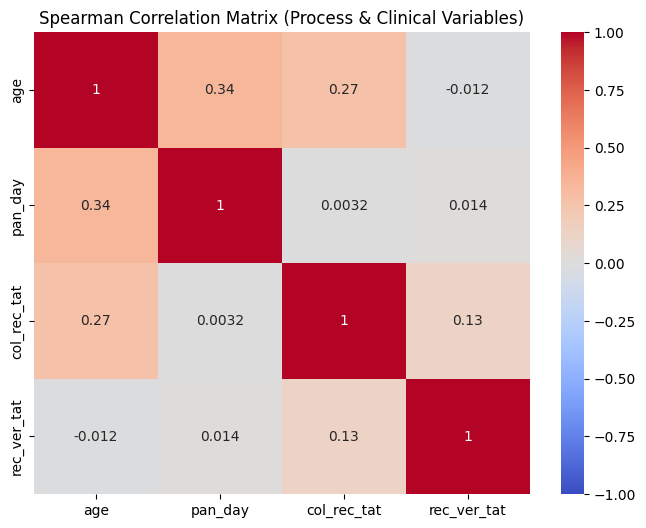


--- 1.2 Variance Inflation Factor (VIF) ---
       feature       VIF
0          age  1.110521
1      pan_day  1.106492
2  col_rec_tat  1.004574
3  rec_ver_tat  1.000722

--- 1.3 Multivariate Outlier Detection (Mahalanobis on Train Set) ---
Extreme multivariate outliers detected in Train Set: 5402 out of 12196.

--- Additional Outlier Diagnostics ---
               count       mean        std  min    1%    5%   50%      95%  \
age          12196.0  14.370581  16.738477  0.0   0.0   0.3   9.0   51.000   
pan_day      12196.0  63.443670  27.241812  7.0  13.0  21.0  65.0  104.000   
col_rec_tat  12196.0   3.370605  18.831552  0.0   0.2   0.3   1.9    7.825   
rec_ver_tat  12196.0   5.558773   5.440476  0.0   2.8   3.2   5.0    9.100   

               99%     max  
age           75.0   119.0  
pan_day      106.0   107.0  
col_rec_tat   23.7  1322.1  
rec_ver_tat   16.1   218.2  

Negative turnaround times:
col_rec_tat    0
rec_ver_tat    0
dtype: int64

MCD outliers: 5402 (44.29% of train

In [6]:
from sklearn.model_selection import train_test_split

# Group-aware Train/Test Split (80% Train, 20% Test)
unique_subjects = df_clean['subject_id'].unique()
train_subjects, test_subjects = train_test_split(unique_subjects, test_size=0.20, random_state=42)

df_train = df_clean[df_clean['subject_id'].isin(train_subjects)].copy()
df_test = df_clean[df_clean['subject_id'].isin(test_subjects)].copy()

print(f"Training Set: {len(df_train)} tests")
print(f"Testing Set:  {len(df_test)} tests\n")

# Define the continuous variables for latent profile analysis
# (ct_result is strictly excluded to prevent leakage)
var_continue = ['age', 'pan_day', 'col_rec_tat', 'rec_ver_tat']
X_train = df_train[var_continue]

print("--- 1.1 Spearman Correlation Matrix (Train Set) ---")
plt.figure(figsize=(8, 6))
sns.heatmap(X_train.corr(method='spearman'), annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Spearman Correlation Matrix (Process & Clinical Variables)')
plt.show()

print("\n--- 1.2 Variance Inflation Factor (VIF) ---")

from statsmodels.api import add_constant
from statsmodels.stats.outliers_influence import (
    variance_inflation_factor
)

X_vif = add_constant(X_train, has_constant='add')

vif_data = pd.DataFrame({
    'feature': var_continue,
    'VIF': [
        variance_inflation_factor(X_vif.values, i)
        for i in range(1, X_vif.shape[1])
    ]
})

print(vif_data)

print("\n--- 1.3 Multivariate Outlier Detection (Mahalanobis on Train Set) ---")
# Fit the robust covariance strictly on the training set to prevent leakage
robust_cov = MinCovDet(random_state=42).fit(X_train)
df_train['mahalanobis'] = robust_cov.mahalanobis(X_train)

# Use the Chi-square distribution to set the threshold (99th percentile)
threshold = chi2.ppf((1-0.01), df=len(var_continue))
df_train['outlier_mahalanobis'] = df_train['mahalanobis'] > threshold
print(f"Extreme multivariate outliers detected in Train Set: {df_train['outlier_mahalanobis'].sum()} out of {len(df_train)}.")

print("\n--- Additional Outlier Diagnostics ---")

print(
    df_train[var_continue]
    .describe(percentiles=[.01, .05, .50, .95, .99])
    .T
)

print("\nNegative turnaround times:")
print(
    (df_train[['col_rec_tat', 'rec_ver_tat']] < 0)
    .sum()
)

n_outliers = df_train['outlier_mahalanobis'].sum()
outlier_pct = 100 * n_outliers / len(df_train)

print(
    f"\nMCD outliers: {n_outliers} "
    f"({outlier_pct:.2f}% of training observations)"
)

print("\n--- 1.4 Yeo-Johnson Transformation ---")
pt = PowerTransformer(method='yeo-johnson')
# Fit and transform ONLY on the training data
X_train_transformed = pt.fit_transform(X_train)
print("Yeo-Johnson transformation applied to strictly correct distribution asymmetry in the Train Set.")

### Repeated Tests per Patient

We investigate the frequency of repeated tests per subject in the training set to assess potential within-patient dependence.

In [7]:
# Repeated-test analysis on the training set
tests_per_subject = df_train.groupby('subject_id').size()

print("Unique patients:", len(tests_per_subject))
print("Patients with more than one test:",
      (tests_per_subject > 1).sum())
print("Percentage of patients with repeated tests:",
      round(100 * (tests_per_subject > 1).mean(), 2))
print("Maximum number of tests per patient:",
      tests_per_subject.max())

print("\nDistribution of tests per patient:")
print(tests_per_subject.value_counts().sort_index())

Unique patients: 9840
Patients with more than one test: 1323
Percentage of patients with repeated tests: 13.45
Maximum number of tests per patient: 20

Distribution of tests per patient:
1     8517
2      885
3      206
4      103
5       47
6       32
7       24
8        9
9        6
10       2
12       3
14       1
15       2
18       1
20       2
Name: count, dtype: int64


# Phase 2: Model-Based Clustering (RQ1)

## RQ1: Robust Latent Testing-Process Profiles

In this phase, we address our first Research Question (RQ1) by identifying latent testing-process profiles among diagnostic test records using robust multivariate clustering. Since some patients underwent multiple tests, the resulting clusters characterize individual testing observations rather than necessarily representing distinct patient groups.

The analysis follows these methodological steps:

1. **Feature Selection & Preprocessing:** We strictly exclude `ct_result` to prevent direct target leakage. The selected demographic and testing-process variables (`age`, `pan_day`, `col_rec_tat`, `rec_ver_tat`) are transformed using the Yeo-Johnson method and standardized (z-score normalization) to ensure comparable scales.

2. **Robust Clustering via TCLUST:** To reduce the influence of extreme multivariate observations on cluster estimation, we apply TCLUST (Trimmed Clustering), trimming α = 0.05 (5%) of the training observations. These trimmed observations are assigned to a separate category (Cluster 0) for subsequent analysis.

3. **Model-Based Clustering & Cluster Selection:** We evaluate the cluster structure using R's `mclust` package and TCLUST's `ctlcurves` diagnostic. The BIC criterion favours an eight-component GMM solution, while we retain k = 3 for parsimony and interpretability. This is a modeling choice rather than the statistically optimal solution according to BIC.

4. **Comparison Between GMM and TCLUST:** The Adjusted Rand Index (ARI = 0.0474) indicates very limited agreement between the two clustering partitions. This difference may reflect their distinct estimation strategies, particularly TCLUST's trimming procedure. However, the low ARI does not independently demonstrate that TCLUST produces a superior clustering solution or confirm its resistance to masking effects.

Overall, the analysis aims to identify interpretable demographic and testing-process profiles while investigating the influence of multivariate outliers on the clustering structure.


R version 4.6.1 (2026-06-24) -- "Happy Hop"
Copyright (C) 2026 The R Foundation for Statistical Computing
Platform: x86_64-pc-linux-gnu

R is free software and comes with ABSOLUTELY NO WARRANTY.
You are welcome to redistribute it under certain conditions.
Type 'license()' or 'licence()' for distribution details.

  Natural language support but running in an English locale

R is a collaborative project with many contributors.
Type 'contributors()' for more information and
'citation()' on how to cite R or R packages in publications.

Type 'demo()' for some demos, 'help()' for on-line help, or
'help.start()' for an HTML browser interface to help.
Type 'q()' to quit R.

> if (!require("mclust")) install.packages("mclust", repos="https://cloud.r-project.org")
Loading required package: mclust
Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
trying URL 'https://cloud.r-project.org/src/contrib/mclust_6.1.3.tar.gz'
Content type 'application/x-gzip' length 27808

   ____ ___  _____/ /_  _______/ /_
  / __ `__ \/ ___/ / / / / ___/ __/
 / / / / / / /__/ / /_/ (__  ) /_  
/_/ /_/ /_/\___/_/\__,_/____/\__/   version 6.1.3
Type 'citation("mclust")' for citing this R package in publications.



fitting ...
  |======================================================================| 100%
--- Mclust Optimal Model Summary ---
---------------------------------------------------- 
Gaussian finite mixture model fitted by EM algorithm 
---------------------------------------------------- 

Mclust VVV (ellipsoidal, varying volume, shape, and orientation) model with 8
components: 

 log-likelihood     n  df     BIC       ICL
      -51862.65 12196 119 -104845 -107720.6

Clustering table:
   1    2    3    4    5    6    7    8 
2083 2293 1221  179 2130 1303 1409 1578 

Mathematical components suggested by max BIC: 8
Note: We proceed with k = 3 for operational interpretability and parsimony.

--- Model-Based Clustering: BIC Model Selection (mclust) ---


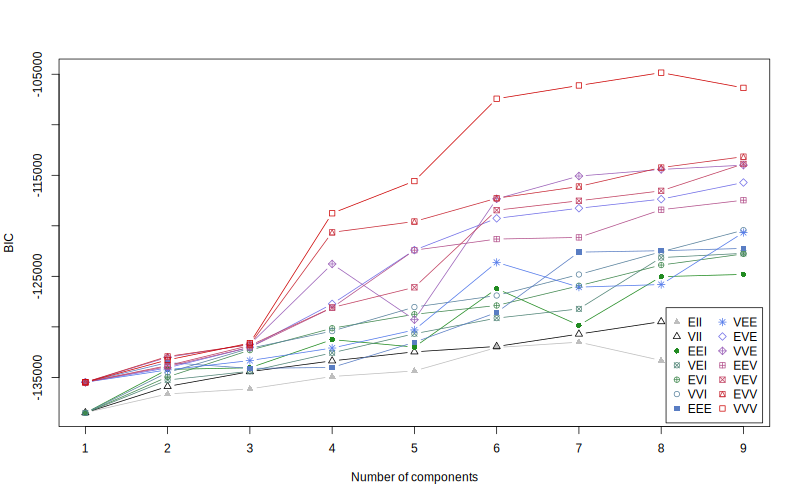

In [8]:
# Ensure mclust is installed in the R environment
!R -e 'if (!require("mclust")) install.packages("mclust", repos="https://cloud.r-project.org")'

# Standardize the transformed Training data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_transformed)

# Convert the scaled array back to a DataFrame for R compatibility
df_train_scaled = pd.DataFrame(X_train_scaled, columns=var_continue)

# R Script to run Mclust
mclust_code = """
library(mclust)

# Set random seed for reproducibility
set.seed(42)

# Run Mclust on the scaled training data
mclust_model <- Mclust(df_train_scaled)


# Print the model summary
cat("--- Mclust Optimal Model Summary ---\n")
print(summary(mclust_model))

# Save the BIC landscape plot
png("mclust_bic.png", width=800, height=500)
plot(mclust_model, what = "BIC")
dev.off()

# Extract the mathematical G suggested by BIC (to be discussed alongside clinical k=3)
math_k <- mclust_model$G
cat(sprintf("\nMathematical components suggested by max BIC: %d\n", math_k))
cat("Note: We proceed with k = 3 for operational interpretability and parsimony.\n")
"""

# Transfer the dataframe to R using rpy2
with localconverter(ro.default_converter + pandas2ri.converter):
    r_df_train_scaled = ro.conversion.py2rpy(df_train_scaled)
ro.globalenv['df_train_scaled'] = r_df_train_scaled

# Execute the R code
ro.r(mclust_code)

# Display the Mclust BIC plot natively in Python
print("\n--- Model-Based Clustering: BIC Model Selection (mclust) ---")
if os.path.exists("mclust_bic.png"):
    display(Image("mclust_bic.png"))
else:
    print("Error generating the mclust plot.")

### Baseline Comparison: Hierarchical Clustering and Standard GMM ($k=3$)

To establish a baseline for our latent profile analysis, we implement a standard Hierarchical Clustering (using Ward's linkage method on the scaled training data) alongside a standard Gaussian Mixture Model (GMM) configured with $k=3$.

Although mathematical criteria such as Mclust's BIC suggested a higher component count to capture local micro-densities, we deliberately fix $k=3$ to maintain full comparability with our robust TCLUST framework and to prioritize testing-process interpretability. We will subsequently evaluate the concordance between these standard GMM profiles and TCLUST using the Adjusted Rand Index (ARI).

--- 2.1 Hierarchical Dendrogram (Train Set Baseline) ---


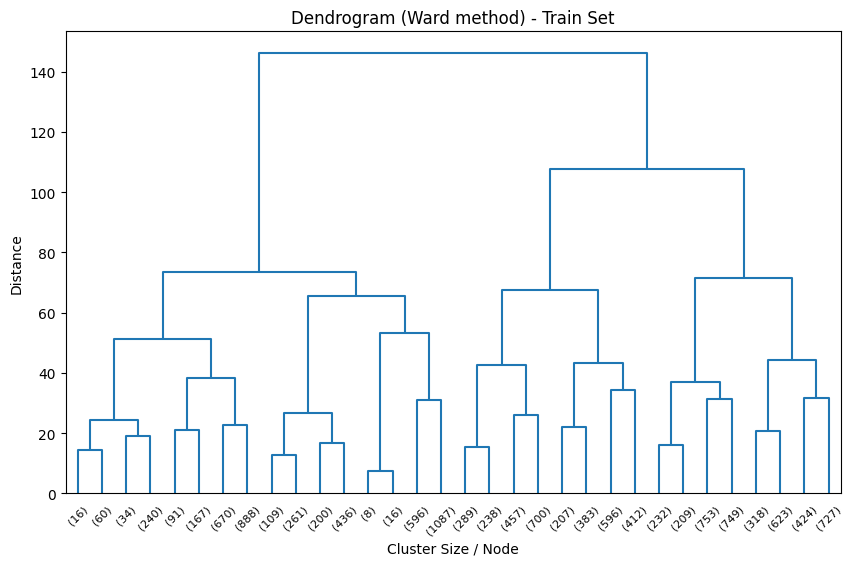


--- 2.2 Internal Evaluation of Baseline GMM ---
Silhouette Score (Baseline GMM k=3): 0.2089
Note: The Adjusted Rand Index (ARI) comparing GMM to TCLUST will be calculated after the TCLUST execution.


In [9]:
# Set the chosen number of clusters for operational interpretability
k_chosen = 3

print("--- 2.1 Hierarchical Dendrogram (Train Set Baseline) ---")
plt.figure(figsize=(10, 6))
# Using ward linkage strictly on the transformed training data
Z = linkage(X_train_scaled, method='ward')
dendrogram(Z, truncate_mode='level', p=4, color_threshold=0)
plt.title('Dendrogram (Ward method) - Train Set')
plt.xlabel('Cluster Size / Node')
plt.ylabel('Distance')
plt.show()

print(f"\n--- 2.2 Internal Evaluation of Baseline GMM ---")
# Fit the baseline GMM strictly on the training set
gmm = GaussianMixture(n_components=k_chosen, random_state=42, covariance_type='full')
df_train['gmm_cluster'] = gmm.fit_predict(X_train_scaled)

# Calculate Silhouette Score on the training set
sil_score = silhouette_score(
    X_train_scaled,
    df_train['gmm_cluster']
)
print(f"Silhouette Score (Baseline GMM k={k_chosen}): {sil_score:.4f}")
print("Note: The Adjusted Rand Index (ARI) comparing GMM to TCLUST will be calculated after the TCLUST execution.")

## Phase 3: Robust Clustering (TCLUST)

Building upon the baseline GMM, we now implement a more advanced Model-Based Clustering approach: **Robust Trimmed Clustering (TCLUST)**.

Conventional Gaussian Mixture Models may be sensitive to extreme observations, which can influence the estimated cluster means and covariance structures. TCLUST provides a robust alternative by jointly estimating the cluster structure and trimming a predefined proportion of observations (`alpha = 0.05` in our analysis).

The trimmed observations are identified during the clustering optimization and do not necessarily correspond to the 5% most distant observations according to a separate outlier measure. These observations are excluded from the estimation of the regular clusters but are retained as Cluster 0 for subsequent descriptive and predictive analyses.

Since TCLUST is uniquely available as a state-of-the-art package in the R ecosystem, we utilize the `rpy2` library to create a seamless interoperability bridge between Python and R. We transfer our scaled DataFrame to the R environment, execute the robust clustering algorithm with $k=3$ (selected for parsimony and interpretability, although the BIC criterion favours an eight-component GMM solution), and retrieve the assigned labels back into our Python pipeline. Notably, TCLUST assigns a specific label (`0`) to the trimmed outliers, allowing us to easily isolate them from the main patient clusters.

Depending on arguments x, k and alpha, this function needs some time to compute.
(Remove this message by setting "trace = 0")
--- 2.3 Robust Clustering (TCLUST) Parameter Diagnostic ---


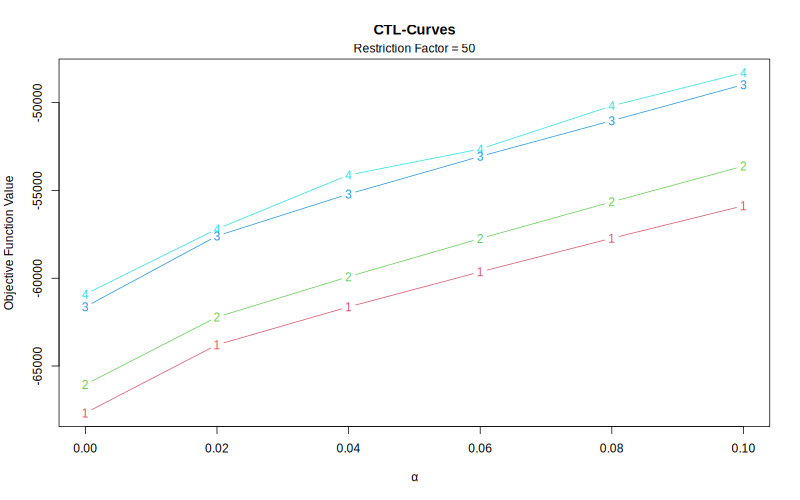


--- Distribution of tests across robust clusters (Train Set) ---
Cluster 0 identifies the trimmed Multivariate Outliers.
tclust_cluster
0.0     610
1.0    6358
2.0    3001
3.0    2227
Name: count, dtype: int64

--- 2.4 External Validation: GMM vs TCLUST ---
Adjusted Rand Index (Agreement between GMM and TCLUST): 0.0474


In [10]:
# Pass the standardized training dataset to R
with localconverter(ro.default_converter + pandas2ri.converter):
    r_data = ro.conversion.py2rpy(df_train_scaled)
ro.globalenv['r_data'] = r_data

# R script to generate ctlcurves and fit TCLUST
tclust_code = """
library(tclust)

# Set random seed for reproducibility
set.seed(42)

# 1. Parameter Justification: Generate ctlcurves
# This visualizes the objective function across different k and alpha values
png("tclust_ctlcurves.png", width=800, height=500)
plot(ctlcurves(r_data, k = 1:4, alpha = seq(0, 0.1, by = 0.02)))
dev.off()

# 2. Fit the Robust Clustering Model (TCLUST)
# k=3 (clinical choice), alpha=0.05 (trimming 5%), restr.fact=50
# Set random seed for reproducibility
set.seed(42)
mod <- tclust(r_data, k = 3, alpha = 0.05, restr.fact = 50)

# Return the cluster assignments
mod$cluster
"""

# Execute the R code and retrieve the labels
cluster_labels = ro.r(tclust_code)

# Save the results as a new column in our Training Set
df_train['tclust_cluster'] = cluster_labels

print("--- 2.3 Robust Clustering (TCLUST) Parameter Diagnostic ---")
if os.path.exists("tclust_ctlcurves.png"):
    display(Image("tclust_ctlcurves.png"))

# Show how many patients ended up in each robust profile
print("\n--- Distribution of tests across robust clusters (Train Set) ---")
print("Cluster 0 identifies the trimmed Multivariate Outliers.")
print(df_train['tclust_cluster'].value_counts().sort_index())

print("\n--- 2.4 External Validation: GMM vs TCLUST ---")
# Exclude the TCLUST outliers (cluster 0) from the comparison matrix
mask = df_train['tclust_cluster'] != 0
ari_score = adjusted_rand_score(df_train.loc[mask, 'gmm_cluster'], df_train.loc[mask, 'tclust_cluster'])
print(f"Adjusted Rand Index (Agreement between GMM and TCLUST): {ari_score:.4f}")

# Standard Logistic Regression Baseline (Fixed-Effects Only)

### Pre-RQ2: Methodological Baseline Comparison

Before building our hierarchical Generalized Linear Mixed Model (GLMM), we establish a single-level baseline using a standard Logistic Regression.

To provide a comparable baseline for the subsequent GLMM, we fit a standard logistic regression on the training set using the same fixed-effect predictors: patient `age` and the robust testing-process profile (`tclust_cluster`), explicitly encoded as a categorical variable through one-hot encoding. The variable `ct_result` is excluded to prevent direct target leakage.

This baseline allows us to compare the out-of-sample predictive performance of standard logistic regression and the clinic-level GLMM. However, performance differences cannot be attributed exclusively to clinic-level random effects, since the models also differ in their estimation procedures and prediction structures.

In [11]:
print("--- PRE-RQ2 PHASE: Baseline Model in Python (Without Random Effects) ---")

# Features: Age and Robust Latent Profile (tclust_cluster treated strictly as a categorical variable)
# CRUCIAL FIX: One-hot encode 'tclust_cluster' (drop_first=True matches R's factor reference level)
X_train_base = pd.get_dummies(
    df_train[['age', 'tclust_cluster']].astype({'tclust_cluster': str}),
    columns=['tclust_cluster'],
    drop_first=True,
    dtype=float
)
y_train = df_train['result_bin'].values

# Fit Classic Logistic Regression strictly on the Train Set (unweighted to match GLMM likelihood)
lr_baseline = LogisticRegression(random_state=42, max_iter=1000)
lr_baseline.fit(X_train_base, y_train)

# Predicted probabilities (In-sample baseline reference)
y_pred_base_train = lr_baseline.predict_proba(X_train_base)[:, 1]

print(f"Log-Loss of the categorical baseline model (Train Set): {log_loss(y_train, y_pred_base_train):.4f}")
print(f"PR-AUC of the categorical baseline model (Train Set):   {average_precision_score(y_train, y_pred_base_train):.4f}")
print(f"ROC-AUC of the categorical baseline model (Train Set):  {roc_auc_score(y_train, y_pred_base_train):.4f}")
print("\nNote: The standard logistic baseline does not explicitly model within-clinic or within-patient dependence.")
print("We therefore fit a clinic-level logistic GLMM and subsequently evaluate an additional patient-level random intercept in a sensitivity analysis.")

--- PRE-RQ2 PHASE: Baseline Model in Python (Without Random Effects) ---
Log-Loss of the categorical baseline model (Train Set): 0.2103
PR-AUC of the categorical baseline model (Train Set):   0.0856
ROC-AUC of the categorical baseline model (Train Set):  0.6202

Note: The standard logistic baseline does not explicitly model within-clinic or within-patient dependence.
We therefore fit a clinic-level logistic GLMM and subsequently evaluate an additional patient-level random intercept in a sensitivity analysis.


## Cluster Profiling and Dimensionality Reduction (PCA)

Having successfully assigned the robust cluster labels (with `0` designating the trimmed outliers), the next step is to interpret and visualize these latent groups.

This block performs three key analytical operations:

1. **Testing-Process Profiling:** We aggregate the continuous demographic and testing-process variables to calculate their mean values within each cluster. This allows us to characterize the distinct patient demographics and testing-process characteristics associated with each group.
2. **Principal Component Analysis (PCA):** We apply PCA to project the multidimensional feature space into two dimensions while maximizing the retained variance.
3. **Visual Exploration:** We generate a scatter plot of the first two principal components, color-coded by the TCLUST labels. This provides a visual representation of the separation between the different testing-process profiles and the distribution of the observations identified as outliers.

--- LATENT TESTING-PROCESS PROFILES (TRAIN SET) ---
                  age  pan_day  col_rec_tat  rec_ver_tat  Test Count  \
tclust_cluster                                                         
0.0             19.47    72.75        13.43        12.46         610   
1.0              8.46    62.36         2.69         5.31        6358   
2.0             35.98    62.08         4.07         4.99        3001   
3.0              0.74    65.84         1.61         5.14        2227   

                Unique Patient Count  
tclust_cluster                        
0.0                              490  
1.0                             5838  
2.0                             2719  
3.0                             1455  




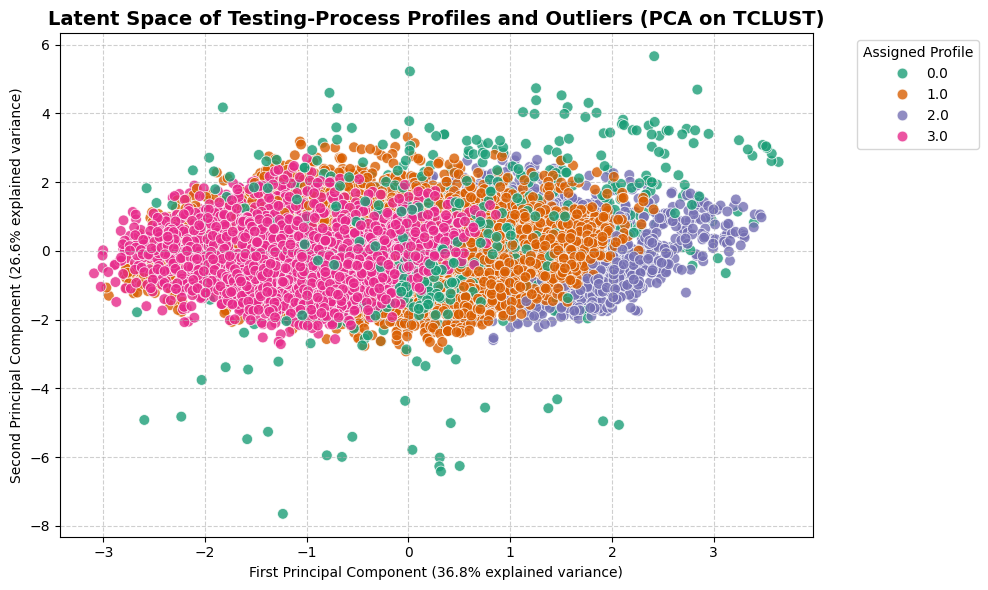

In [12]:
print("--- LATENT TESTING-PROCESS PROFILES (TRAIN SET) ---")
# Calculate the mean of variables to understand differences between groups
cluster_profile = df_train.groupby('tclust_cluster')[var_continue].mean()

# Number of tests in each cluster
cluster_profile['Test Count'] = df_train.groupby('tclust_cluster').size()

# Number of distinct patients in each cluster
cluster_profile['Unique Patient Count'] = (
    df_train.groupby('tclust_cluster')['subject_id'].nunique()
)

print(cluster_profile.round(2))
print("\n")

# PRINCIPAL COMPONENT ANALYSIS (PCA)
# Reduce the multidimensional feature space into 2 dimensions to plot them on a graph
pca = PCA(n_components=2)
# CRUCIAL: Use the scaled training data
X_pca = pca.fit_transform(X_train_scaled)
df_train['PCA1'] = X_pca[:, 0]
df_train['PCA2'] = X_pca[:, 1]

# CLUSTER PLOT
plt.figure(figsize=(10, 6))
# Use a bright color palette to visually separate the profiles
sns.scatterplot(x='PCA1', y='PCA2', hue='tclust_cluster', palette='Dark2', data=df_train, s=60, alpha=0.8)

plt.title('Latent Space of Testing-Process Profiles and Outliers (PCA on TCLUST)', fontsize=14, fontweight='bold')
plt.xlabel(f'First Principal Component ({pca.explained_variance_ratio_[0]*100:.1f}% explained variance)')
plt.ylabel(f'Second Principal Component ({pca.explained_variance_ratio_[1]*100:.1f}% explained variance)')
plt.legend(title='Assigned Profile', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## RQ2: Mixed-Effects Logistic Regression (GLMM)

Having established a predictive baseline and identified robust testing-process profiles, we address our second Research Question (RQ2) by fitting a Generalized Linear Mixed Model (GLMM).

The dataset has a hierarchical structure, as diagnostic tests are associated with different clinics or specimen-collection units (`clinic_name`) within the CHOP healthcare setting. Observations collected within the same unit may share common characteristics, such as testing procedures or patient populations.

We therefore use a logistic GLMM with:

1. **Fixed Effects (`age + tclust_cluster`):** To investigate the association between patient age, testing-process profiles, and COVID-19 test positivity.
2. **Random Effects (`1 | clinic_name`):** To allow the baseline probability of a positive test to vary across clinics or specimen-collection units.
3. **Variance Partition Coefficient (VPC):** To estimate the proportion of latent-scale variance associated with differences between collection units.

The VPC is interpreted on the latent logistic scale and does not represent an exact percentage of observed outcome variability explained by clinics.

### Modeling Choice for Random Effects in GLMM

We include a random intercept for `clinic_name` to account for potential heterogeneity across clinics and specimen-collection units within the CHOP healthcare setting.

The dataset also contains repeated tests for some subjects. Therefore, the clinic-level random intercept does not necessarily account for all within-patient dependence.

We investigate the frequency of repeated observations and assess whether this dependence may affect the interpretation of the model.

In [13]:
# Transfer the TRAINING dataset from Python to R to prevent Data Leakage
with localconverter(ro.default_converter + pandas2ri.converter):
    r_df_train = ro.conversion.py2rpy(df_train)

ro.globalenv['df_train'] = r_df_train

# Write and execute the R code for the GLMM
glmm_code = '''
    library(lme4)

    # Ensure that R reads these columns as categories (Factors) and not as numeric
    df_train$clinic_name <- as.factor(df_train$clinic_name)
    df_train$tclust_cluster <- as.factor(df_train$tclust_cluster)

    # Build the Logistic GLMM
    # result_bin = Y (Target: Positive/Negative)
    # age + tclust_cluster = Fixed Effects (strictly excluding ct_result)
    # (1 | clinic_name) = Random Intercept for the clinic
    model <- glmer(result_bin ~ age + tclust_cluster + (1 | clinic_name),
                   data = df_train,
                   family = binomial,
                   control = glmerControl(optimizer="bobyqa", optCtrl=list(maxfun=100000)))

    # Extract the main results
    print(summary(model))

    cat("\n======================================================\n")

    # Calculate the Variance Partition Coefficient (VPC / ICC)
    var_u <- as.numeric(VarCorr(model))
    vpc <- var_u / (var_u + (pi^2 / 3))

    cat(sprintf("Random Effect Variance (Clinic): %.4f\n", var_u))
    cat(sprintf("Variance Partition Coefficient (VPC): %.2f%%\n", vpc * 100))
    cat("======================================================\n")
'''

# Print the results
ro.r(glmm_code)

Generalized linear mixed model fit by maximum likelihood (Laplace
  Approximation) [glmerMod]
 Family: binomial  ( logit )
Formula: result_bin ~ age + tclust_cluster + (1 | clinic_name)
   Data: df_train
Control: glmerControl(optimizer = "bobyqa", optCtrl = list(maxfun = 1e+05))

      AIC       BIC    logLik -2*log(L)  df.resid 
   4982.9    5027.4   -2485.5    4970.9     12190 

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-0.9269 -0.2839 -0.2213 -0.1911 11.6466 

Random effects:
 Groups      Name        Variance Std.Dev.
 clinic_name (Intercept) 2.207    1.486   
Number of obs: 12196, groups:  clinic_name, 86

Fixed effects:
                 Estimate Std. Error z value Pr(>|z|)    
(Intercept)     -2.999502   0.282378 -10.622  < 2e-16 ***
age              0.004503   0.003151   1.429  0.15308    
tclust_cluster1 -0.892564   0.163280  -5.466 4.59e-08 ***
tclust_cluster2 -0.466329   0.168852  -2.762  0.00575 ** 
tclust_cluster3 -1.098775   0.201407  -5.455 4.88e-08 ***
-

## Interpretation of GLMM Fixed Effects: Odds Ratios (OR)

The fixed-effect coefficients of a logistic GLMM are expressed on the log-odds scale, making their direct interpretation less intuitive. To facilitate the interpretation of the associations between predictors and COVID-19 test positivity, we convert these coefficients into Odds Ratios (OR).

This block performs three main operations:

1. **Coefficient Extraction:** We extract the estimated fixed-effect coefficients from the fitted GLMM using the `lme4` package.
2. **Odds Ratio Conversion:** We exponentiate the coefficients to obtain Odds Ratios. For example, an OR of 1.5 corresponds to a 50% increase in the odds of testing positive for a one-unit increase in a continuous predictor, holding the other predictors and the clinic-level random effect constant. For categorical predictors, Odds Ratios represent comparisons with the reference category.
3. **Structured Reporting:** We present the estimated log-odds coefficients, Odds Ratios, and associated p-values in a summary table to facilitate the interpretation of age and testing-process profile associations with test positivity.

These estimates describe statistical associations rather than causal effects. Furthermore, Odds Ratios should not be interpreted as direct changes in probability or relative risk.

In [14]:
# Ensure rpy2 communicates correctly with pandas
import rpy2.robjects as ro
from rpy2.robjects import pandas2ri
from rpy2.robjects.conversion import localconverter

pandas2ri.activate()

# Pass the strictly isolated TRAINING dataset to R
with localconverter(ro.default_converter + pandas2ri.converter):
    r_df_train = ro.conversion.py2rpy(df_train)

ro.globalenv['df_train'] = r_df_train

# Extract Odds Ratios from the previously fitted GLMM

or_code = """
library(lme4)

# Reuse the model fitted in the RQ2 section
sum_mod <- summary(model)
coefs <- sum_mod$coefficients

# Calculate Odds Ratios
OR <- exp(coefs[, "Estimate"])

results_table <- data.frame(
  Log_Odds = coefs[, "Estimate"],
  Odds_Ratio = OR,
  P_Value = coefs[, "Pr(>|z|)"]
)

cat("\\n--- FIXED EFFECTS AND ODDS RATIOS ---\\n")
print(round(results_table, 4))

# Clinic-level random-effect variance
var_u <- as.numeric(VarCorr(model)$clinic_name)
vpc <- var_u / (var_u + (pi^2 / 3))

cat("\\n--- CLINIC-LEVEL HETEROGENEITY ---\\n")
cat(sprintf("Clinic Variance: %.4f\\n", var_u))
cat(sprintf("Latent-scale VPC: %.2f%%\\n", vpc * 100))
"""

ro.r(or_code)


--- FIXED EFFECTS AND ODDS RATIOS ---
                Log_Odds Odds_Ratio P_Value
(Intercept)      -2.9995     0.0498  0.0000
age               0.0045     1.0045  0.1531
tclust_cluster1  -0.8926     0.4096  0.0000
tclust_cluster2  -0.4663     0.6273  0.0057
tclust_cluster3  -1.0988     0.3333  0.0000

--- CLINIC-LEVEL HETEROGENEITY ---
Clinic Variance: 2.2074
Latent-scale VPC: 40.15%


### Patient-Level Random Effects: Sensitivity Analysis

We evaluate whether accounting for repeated tests within subjects changes the estimated fixed effects and random-effect structure of the GLMM.

In [15]:

sensitivity_code = """
library(lme4)

# Ensure consistent categorical encoding
df_train$tclust_cluster <- as.factor(df_train$tclust_cluster)
df_train$clinic_name <- as.factor(df_train$clinic_name)
df_train$subject_id <- as.factor(df_train$subject_id)

# Original model: clinic-level random intercept
model_clinic <- model

# Extended model: clinic + patient random intercepts
model_clinic_subject <- glmer(
  result_bin ~ age + tclust_cluster +
    (1 | clinic_name) + (1 | subject_id),
  data = df_train,
  family = binomial,
  control = glmerControl(
    optimizer = "bobyqa",
    optCtrl = list(maxfun = 100000)
  )
)

cat("\n--- EXTENDED GLMM ---\n")
print(summary(model_clinic_subject))

cat("\n--- SINGULAR FIT ---\n")
print(isSingular(model_clinic_subject))

cat("\n--- RANDOM EFFECT VARIANCES ---\n")
print(VarCorr(model_clinic_subject))

cat("\n--- FIXED EFFECTS COMPARISON ---\n")
print(fixef(model_clinic))
print(fixef(model_clinic_subject))

cat("\n--- MODEL COMPARISON (AIC) ---\n")
print(AIC(model_clinic, model_clinic_subject))
"""

ro.r(sensitivity_code)



--- EXTENDED GLMM ---
Generalized linear mixed model fit by maximum likelihood (Laplace
  Approximation) [glmerMod]
 Family: binomial  ( logit )
Formula: result_bin ~ age + tclust_cluster + (1 | clinic_name) + (1 |  
    subject_id)
   Data: df_train
Control: glmerControl(optimizer = "bobyqa", optCtrl = list(maxfun = 1e+05))

      AIC       BIC    logLik -2*log(L)  df.resid 
   4925.0    4976.9   -2455.5    4911.0     12189 

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-1.3659 -0.2584 -0.2067 -0.1714  6.5802 

Random effects:
 Groups      Name        Variance Std.Dev.
 subject_id  (Intercept) 1.373    1.172   
 clinic_name (Intercept) 1.737    1.318   
Number of obs: 12196, groups:  subject_id, 9840; clinic_name, 86

Fixed effects:
                 Estimate Std. Error z value Pr(>|z|)    
(Intercept)     -3.486792   0.284731 -12.246  < 2e-16 ***
age              0.002942   0.003630   0.810   0.4177    
tclust_cluster1 -0.909910   0.183687  -4.954 7.29e-07 ***
tclust_c

### Interpretation of the Patient-Level Sensitivity Analysis

The extended GLMM includes random intercepts for both clinic and patient, accounting for the potential dependence among repeated tests from the same individual.

The extended model achieves a lower AIC (4925.03) than the original clinic-level GLMM (4982.92), indicating an improvement in model fit despite the additional random-effect variance parameter.

The estimated patient-level variance (1.372) suggests meaningful heterogeneity between individuals, while the clinic-level variance remains substantial (1.737). Furthermore, the extended model does not exhibit a singular fit, supporting the identifiability of both random-effect components.

The fixed-effect estimates remain broadly similar across the two models, suggesting that the main associations are reasonably stable after accounting for repeated patient measurements.

Overall, this sensitivity analysis indicates that patient-level dependence is relevant to the statistical modeling of the data. However, the lower AIC does not necessarily imply superior out-of-sample predictive performance, which must be evaluated separately.

## GLMM Diagnostics via DHARMa

Standard residual analysis is notoriously difficult for logistic mixed-effects models. To properly validate our GLMM, we use the `DHARMa` package, which simulates standardized residuals from the fitted model.

We assess three key diagnostics:
1. **Uniformity (KS Test):** Checks if the overall distribution of residuals matches the expected theoretical distribution.
2. **Dispersion Test:** Checks for overdispersion or underdispersion (common in medical count/binomial data).
3. **Outlier Test:** Checks for an excess of residual outliers outside the simulation envelope.

Note: In earlier iterations, data leakage caused artificial complete separation, resulting in a significant KS deviation. By isolating valid predictors, we expect a more reliable structural fit.

(as ‘lib’ is unspecified)















	‘/tmp/Rtmpiup8e3/downloaded_packages’


Note that the default setting in simulateResiduals was changed to conditional simulations since version 0.5.0. This is likely to change residual calculations for all hierarchical (in particular random effect) models. If you want to switch back to the old package version defaults, please use the argument simulateREs = "user-specified" in simulateResiduals(). For more details, see ?simulateREsiduals.

Attaching package: ‘DHARMa’



    getData





--- MODEL DIAGNOSTICS (DHARMa on Train Set) ---


Diagnostic plots have been successfully generated.
Please review the KS test, Dispersion test, and Outlier test p-values in the plot.
(A p-value > 0.05 indicates no significant deviation from the model assumptions).


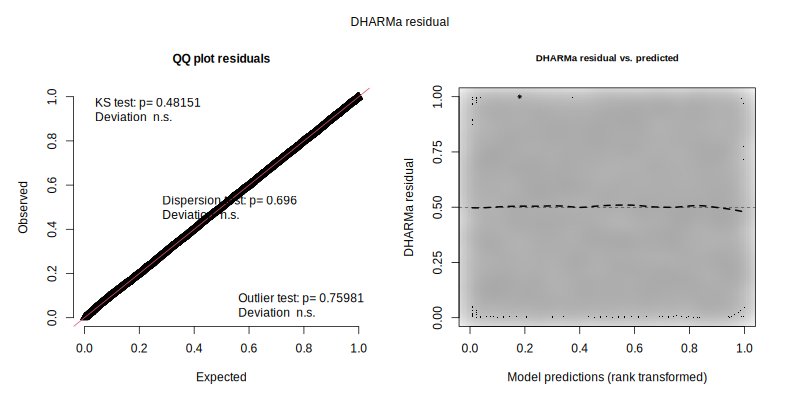

In [16]:
# ADVANCED PHASE: GLMM Diagnostics via DHARMa
dharma_code = '''
    # Install package for GLMM diagnostics if missing
    if (!requireNamespace("DHARMa", quietly = TRUE)) install.packages("DHARMa", repos="https://cloud.r-project.org")
    library(DHARMa)

    cat("\\n--- MODEL DIAGNOSTICS (DHARMa on Train Set) ---\\n")

    # Simulate residuals for the logistic mixed model
    simulated_res <- simulateResiduals(fittedModel = model, n = 250)

    # Run and print standard tests
    testDispersion(simulated_res)

    # Save the diagnostic plot
    png("dharma_diagnostics.png", width=800, height=400)
    plot(simulated_res)
    dev.off()

    cat("Diagnostic plots have been successfully generated.\\n")
    cat("Please review the KS test, Dispersion test, and Outlier test p-values in the plot.\\n")
    cat("(A p-value > 0.05 indicates no significant deviation from the model assumptions).\\n")
'''
ro.r(dharma_code)

# Display the plot saved by R directly in Python
display(Image("dharma_diagnostics.png"))

## Predictive Validation: Out-of-Sample Evaluation (RQ3)

To address our third Research Question (RQ3), we evaluate the predictive performance of the hierarchical GLMM on an independent test set, with subjects separated between training and testing.

The evaluation follows four main steps:

1. **Out-of-Sample Preprocessing:** The test observations are transformed using the Yeo-Johnson transformer and StandardScaler fitted exclusively on the training data.

2. **Cluster Assignment:** TCLUST profiles are approximated on the test set using a 1-nearest-neighbor classifier fitted on non-trimmed training observations. An additional distance threshold, derived from the training data, is used to identify potentially anomalous observations (Cluster 0). This procedure is an approximation rather than the original TCLUST classification rule.

3. **GLMM Prediction:** The fitted GLMM generates predicted probabilities on the held-out test set. The prediction procedure accommodates previously unseen clinic levels through `allow.new.levels = TRUE`.

4. **Predictive Evaluation:** We assess discrimination and prediction error using PR-AUC, ROC-AUC, Brier Score, a confusion matrix, and classification metrics.

### Choice of GLMM for Out-of-Sample Prediction

The primary predictive evaluation uses the clinic-level GLMM, while the extended model including patient-level random intercepts is retained as a sensitivity analysis.

Since the train/test split separates patients, the patient-specific random effects estimated during training are not available for individuals in the test set. The clinic-level GLMM is therefore retained as the primary predictive model, allowing us to evaluate the contribution of clinic-level heterogeneity without relying on patient-specific effects estimated from previous observations.

Although the extended GLMM achieves a lower AIC, this indicates better in-sample model fit rather than necessarily better predictive performance on unseen patients.

Consequently, the reported predictive metrics refer to the clinic-level GLMM, and no claim is made that it outperforms the extended model in out-of-sample prediction.

### Methodological Note on Threshold Selection

The F1-maximizing classification threshold is selected using in-sample predictions from the training data and is subsequently applied without modification to the independent test set.

Although the test set is not used for threshold optimization, the in-sample procedure may yield an optimistic threshold estimate. This limitation is considered when interpreting precision, recall, and F1-score.

### Methodological Note on Outlier Proportion

The TCLUST model applies a 5% trimming proportion during training. However, approximately 8.89% of test observations are assigned to Cluster 0 using the additional nearest-neighbor distance rule

The difference arises because the out-of-sample assignment uses a distance-based approximation rather than the original TCLUST trimming optimization. Consequently, these proportions are not directly equivalent.

--- 3.1 TEST SET PREPARATION & ROBUST OUTLIER MAPPING (OUT-OF-SAMPLE) ---
Training nearest-neighbour 95th percentile threshold: 0.3171

Distribution of TCLUST profiles in Test Set:
tclust_cluster
0.0     269
1.0    1570
2.0     671
3.0     517
Name: count, dtype: int64

Test observations mapped to Cluster 0: 269/3027 (8.89%)

Test Set successfully transformed using Train-fitted preprocessing and mapped to the robust TCLUST profiles.

--- 3.2 GLMM PREDICTION (OUT-OF-SAMPLE) ---

--- 3.3 THRESHOLD OPTIMIZATION (STRICTLY ON TRAIN SET) ---
Selected Optimal Threshold (from Train Set): 0.0765

--- 3.4 MULTI-METRIC EVALUATION (OUT-OF-SAMPLE TEST SET) ---
PR-AUC (Test Set):  0.0962
ROC-AUC (Test Set): 0.5989
Brier Score (Test Set): 0.0576


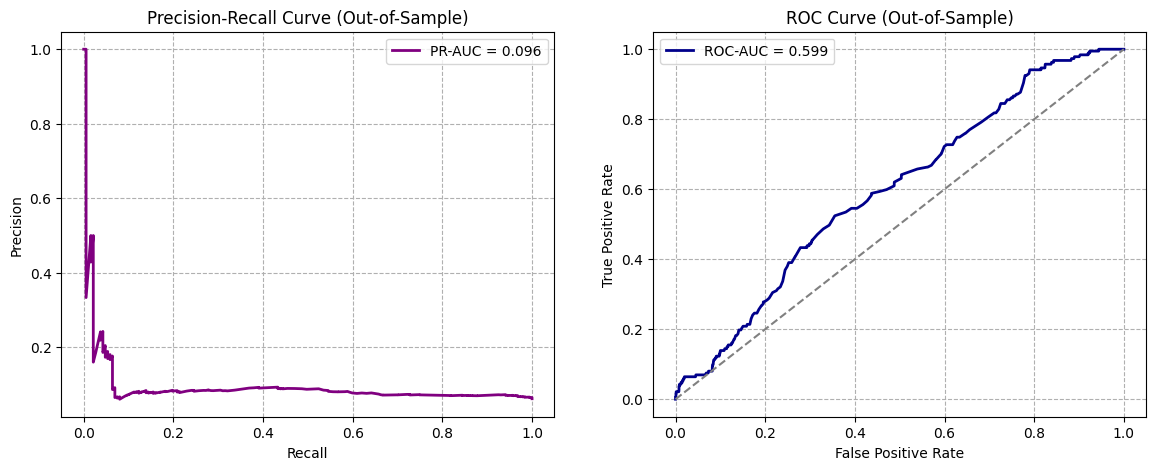

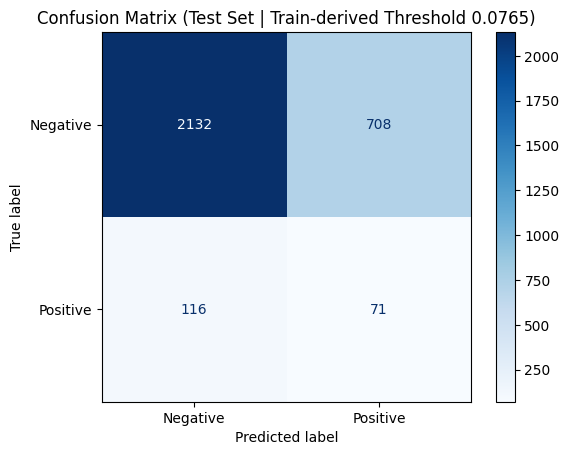


--- FINAL CLASSIFICATION REPORT (OUT-OF-SAMPLE) ---
              precision    recall  f1-score   support

    Negative       0.95      0.75      0.84      2840
    Positive       0.09      0.38      0.15       187

    accuracy                           0.73      3027
   macro avg       0.52      0.57      0.49      3027
weighted avg       0.90      0.73      0.80      3027



In [17]:
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors

print("--- 3.1 TEST SET PREPARATION & ROBUST OUTLIER MAPPING (OUT-OF-SAMPLE) ---")

# ============================================================
# PREPROCESS TEST SET USING TRAIN-FITTED TRANSFORMATIONS
# ============================================================

X_test = df_test[var_continue]

# Apply Yeo-Johnson fitted ONLY on Training Set
X_test_transformed = pt.transform(X_test)

# Apply StandardScaler fitted ONLY on Training Set
# TCLUST was trained on X_train_scaled, so Test data must be
# represented in exactly the same feature space.
X_test_scaled = scaler.transform(X_test_transformed)


# ============================================================
# USE ONLY NON-TRIMMED TCLUST TRAINING OBSERVATIONS
# ============================================================

mask_train = (df_train['tclust_cluster'] != 0).to_numpy()

X_train_valid = X_train_scaled[mask_train]
y_train_valid = df_train.loc[
    df_train['tclust_cluster'] != 0,
    'tclust_cluster'
].to_numpy()


# ============================================================
# ASSIGN TEST OBSERVATIONS TO THE NEAREST ROBUST CLUSTER
# ============================================================

knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(X_train_valid, y_train_valid)

assigned_clusters = knn.predict(X_test_scaled)


# ============================================================
# DEFINE OUTLIER THRESHOLD FROM TRAINING DATA
# ============================================================

# IMPORTANT:
# For training observations we use TWO neighbours.
# The first neighbour is the observation itself (distance = 0),
# therefore the SECOND neighbour gives the actual nearest-neighbour
# distance required to construct the threshold.

nn_train = NearestNeighbors(n_neighbors=2)
nn_train.fit(X_train_valid)

train_distances, _ = nn_train.kneighbors(X_train_valid)

# Column 0 = observation itself
# Column 1 = actual nearest different observation
train_nn_distances = train_distances[:, 1]

# Robust threshold defined only from the Training Set
outlier_threshold = np.percentile(train_nn_distances, 95)


# ============================================================
# CALCULATE TEST-TO-TRAIN DISTANCES
# ============================================================

test_distances, _ = nn_train.kneighbors(
    X_test_scaled,
    n_neighbors=1
)

test_nn_distances = test_distances[:, 0]


# ============================================================
# ASSIGN CLUSTER 0 TO OUT-OF-SAMPLE ANOMALOUS OBSERVATIONS
# ============================================================

final_test_clusters = np.where(
    test_nn_distances > outlier_threshold,
    0,
    assigned_clusters
)

df_test['tclust_cluster'] = final_test_clusters


# ============================================================
# DIAGNOSTIC OUTPUT
# ============================================================

print(f"Training nearest-neighbour 95th percentile threshold: "
      f"{outlier_threshold:.4f}")

print("\nDistribution of TCLUST profiles in Test Set:")
print(
    df_test['tclust_cluster']
    .value_counts()
    .sort_index()
)

n_test_outliers = (df_test['tclust_cluster'] == 0).sum()

print(
    f"\nTest observations mapped to Cluster 0: "
    f"{n_test_outliers}/{len(df_test)} "
    f"({100*n_test_outliers/len(df_test):.2f}%)"
)

print(
    "\nTest Set successfully transformed using Train-fitted "
    "preprocessing and mapped to the robust TCLUST profiles."
)

print("\n--- 3.2 GLMM PREDICTION (OUT-OF-SAMPLE) ---")
# Transfer Test Set to R
with localconverter(ro.default_converter + pandas2ri.converter):
    r_df_test = ro.conversion.py2rpy(df_test)
ro.globalenv['df_test'] = r_df_test

# R code to predict strictly on NEW data
predict_code = '''
    df_test$clinic_name <- as.factor(df_test$clinic_name)
    df_test$tclust_cluster <- as.factor(df_test$tclust_cluster)

    # Predict on Test Set. allow.new.levels=TRUE handles clinics potentially missing in Train
    pred_prob_test <- predict(model, newdata = df_test, type = "response", allow.new.levels = TRUE)

    # Also get in-sample predictions for training threshold optimization
    pred_prob_train <- fitted(model)

    list(test = as.numeric(pred_prob_test), train = as.numeric(pred_prob_train))
'''
preds_r = ro.r(predict_code)
y_pred_prob_test = np.array(preds_r.rx2('test'))
y_pred_prob_train = np.array(preds_r.rx2('train'))

y_true_test = df_test['result_bin'].values
y_true_train = df_train['result_bin'].values

print("\n--- 3.3 THRESHOLD OPTIMIZATION (STRICTLY ON TRAIN SET) ---")
# CRUCIAL FIX: Determine optimal threshold maximizing F1 on the Training Set only,
# then apply it blindly to the Test Set.
precision_tr, recall_tr, thresholds_tr = precision_recall_curve(y_true_train, y_pred_prob_train)
f1_scores_tr = (2 * precision_tr * recall_tr) / (precision_tr + recall_tr + 1e-8)
best_idx_tr = np.argmax(f1_scores_tr)
best_threshold = thresholds_tr[best_idx_tr] if best_idx_tr < len(thresholds_tr) else 0.5

print(f"Selected Optimal Threshold (from Train Set): {best_threshold:.4f}")

print("\n--- 3.4 MULTI-METRIC EVALUATION (OUT-OF-SAMPLE TEST SET) ---")
pr_auc = average_precision_score(y_true_test, y_pred_prob_test)
roc_auc = roc_auc_score(y_true_test, y_pred_prob_test)
brier = brier_score_loss(y_true_test, y_pred_prob_test)

print(f"PR-AUC (Test Set):  {pr_auc:.4f}")
print(f"ROC-AUC (Test Set): {roc_auc:.4f}")
print(f"Brier Score (Test Set): {brier:.4f}")

# CHARTS
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

precision_te, recall_te, _ = precision_recall_curve(y_true_test, y_pred_prob_test)
axes[0].plot(recall_te, precision_te, color='purple', lw=2, label=f'PR-AUC = {pr_auc:.3f}')
axes[0].set_xlabel('Recall')
axes[0].set_ylabel('Precision')
axes[0].set_title('Precision-Recall Curve (Out-of-Sample)')
axes[0].legend()
axes[0].grid(True, linestyle='--')

fpr, tpr, _ = roc_curve(y_true_test, y_pred_prob_test)
axes[1].plot(fpr, tpr, color='darkblue', lw=2, label=f'ROC-AUC = {roc_auc:.3f}')
axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve (Out-of-Sample)')
axes[1].legend()
axes[1].grid(True, linestyle='--')
plt.show()

# Confusion matrix using the threshold derived exclusively from the Train Set
y_pred_class_test = (y_pred_prob_test >= best_threshold).astype(int)
cm = confusion_matrix(y_true_test, y_pred_class_test)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative", "Positive"])
disp.plot(cmap=plt.cm.Blues)
plt.title(f'Confusion Matrix (Test Set | Train-derived Threshold {best_threshold:.4f})')
plt.show()

print("\n--- FINAL CLASSIFICATION REPORT (OUT-OF-SAMPLE) ---")
print(classification_report(y_true_test, y_pred_class_test, target_names=["Negative", "Positive"]))

## Comparative Out-of-Sample Evaluation: Baseline vs. Hierarchical GLMM

To evaluate the potential predictive contribution of accounting for clinic-level heterogeneity, we compare the hierarchical GLMM with a standard logistic regression model on the independent test set.

The comparison follows three main principles:

1. **Identical Fixed-Effect Predictors:** Both models include the same predictors (`age` and categorical `tclust_cluster`), allowing a comparison without differences in the selected fixed-effect variables.

2. **Consistent Out-of-Sample Evaluation:** Both models are evaluated on the same held-out test set using identical performance metrics: PR-AUC, ROC-AUC, and Brier Score.

3. **Assessment of the Mixed-Effects Structure:** The comparison investigates whether incorporating clinic-level random intercepts is associated with improved predictive performance. However, observed differences cannot be attributed exclusively to the random effects, since the models also differ in their estimation procedures and prediction structures.

This evaluation provides evidence about the relative predictive performance of the two modeling approaches, without implying that one model is universally superior.

In [18]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

print("--- 4. COMPARISON PHASE: Standard Logistic Regression Baseline (Out-of-Sample) ---")

# CRUCIAL FIX: Ensure identical feature representation.
# We use 'tclust_cluster' encoded as a categorical factor, exactly like in the GLMM.
df_train['tclust_cluster_cat'] = pd.Categorical(df_train['tclust_cluster'])
df_test['tclust_cluster_cat'] = pd.Categorical(df_test['tclust_cluster'])

# Fit a standard Logistic Regression (without random effects) on the Training Set
baseline_formula = "result_bin ~ age + C(tclust_cluster_cat)"
lr_model = smf.logit(formula=baseline_formula, data=df_train).fit(disp=0)

# Predict probabilities on the Test Set
y_pred_base_test = lr_model.predict(df_test)
y_true_test = df_test['result_bin'].values

# Evaluate baseline out-of-sample performance
base_pr_auc = average_precision_score(y_true_test, y_pred_base_test)
base_roc_auc = roc_auc_score(y_true_test, y_pred_base_test)
base_brier = brier_score_loss(y_true_test, y_pred_base_test)

print("\n--- Standard Logistic Regression Baseline (Test Set) ---")
print(f"Baseline PR-AUC:  {base_pr_auc:.4f}")
print(f"Baseline ROC-AUC: {base_roc_auc:.4f}")
print(f"Baseline Brier:   {base_brier:.4f}")

print("\n--- Hierarchical GLMM (From RQ3 for direct comparison) ---")
print(f"GLMM PR-AUC:      {pr_auc:.4f}")
print(f"GLMM ROC-AUC:     {roc_auc:.4f}")
print(f"GLMM Brier:       {brier:.4f}")
print("\nConclusion: The GLMM shows modest improvements in out-of-sample predictive performance compared with standard logistic regression. However, these differences cannot be attributed exclusively to clinic-level random effects.")

--- 4. COMPARISON PHASE: Standard Logistic Regression Baseline (Out-of-Sample) ---

--- Standard Logistic Regression Baseline (Test Set) ---
Baseline PR-AUC:  0.0705
Baseline ROC-AUC: 0.5643
Baseline Brier:   0.0582

--- Hierarchical GLMM (From RQ3 for direct comparison) ---
GLMM PR-AUC:      0.0962
GLMM ROC-AUC:     0.5989
GLMM Brier:       0.0576

Conclusion: The GLMM shows modest improvements in out-of-sample predictive performance compared with standard logistic regression. However, these differences cannot be attributed exclusively to clinic-level random effects.


## Bootstrap Uncertainty of Predictive Performance

We estimate 95% bootstrap confidence intervals for the differences in predictive performance between the GLMM and standard logistic regression.

Resampling is performed at the subject level to preserve the dependence between repeated tests belonging to the same patient.

In [19]:
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss
)
import numpy as np

rng = np.random.default_rng(42)
B = 500

# Group test observations by patient
patient_groups = list(
    df_test.groupby('subject_id', sort=False).indices.values()
)

y = np.asarray(y_true_test)
p_glmm = np.asarray(y_pred_prob_test)
p_base = np.asarray(y_pred_base_test)

diff_pr = []
diff_roc = []
diff_brier = []

for _ in range(B):

    sampled_groups = rng.integers(
        0, len(patient_groups),
        size=len(patient_groups)
    )

    idx = np.concatenate([
        patient_groups[i] for i in sampled_groups
    ])

    y_b = y[idx]
    glmm_b = p_glmm[idx]
    base_b = p_base[idx]

    if len(np.unique(y_b)) < 2:
        continue

    diff_pr.append(
        average_precision_score(y_b, glmm_b)
        - average_precision_score(y_b, base_b)
    )

    diff_roc.append(
        roc_auc_score(y_b, glmm_b)
        - roc_auc_score(y_b, base_b)
    )

    diff_brier.append(
        brier_score_loss(y_b, base_b)
        - brier_score_loss(y_b, glmm_b)
    )

for name, values in [
    ("PR-AUC improvement", diff_pr),
    ("ROC-AUC improvement", diff_roc),
    ("Brier improvement", diff_brier)
]:
    ci = np.percentile(values, [2.5, 97.5])

    print(f"\n{name}")
    print(f"Mean difference: {np.mean(values):.4f}")
    print(f"95% Bootstrap CI: [{ci[0]:.4f}, {ci[1]:.4f}]")


PR-AUC improvement
Mean difference: 0.0265
95% Bootstrap CI: [0.0074, 0.0510]

ROC-AUC improvement
Mean difference: 0.0341
95% Bootstrap CI: [-0.0019, 0.0722]

Brier improvement
Mean difference: 0.0006
95% Bootstrap CI: [-0.0002, 0.0014]


## Parameter Uncertainty: Wald Confidence Intervals for GLMM

To assess the uncertainty of the GLMM fixed-effect estimates, we calculate 95% Wald confidence intervals.

These intervals are based on the asymptotic normal approximation of the estimated regression coefficients. Although computationally efficient, their reliability depends on the regularity assumptions underlying the model.

We also use a separate patient-level bootstrap procedure to quantify uncertainty in the out-of-sample predictive performance differences between the GLMM and the standard logistic regression.

The bootstrap of predictive metrics does not replace a bootstrap analysis of the GLMM coefficients.

This represents a refinement of our initial project proposal. Since our final research question focuses on comparing the out-of-sample predictive performance of the GLMM and standard logistic regression, we prioritize patient-level bootstrap confidence intervals for the differences in predictive metrics. For the GLMM coefficients, we instead report Wald confidence intervals, acknowledging their dependence on asymptotic assumptions. Therefore, the two approaches address different sources of uncertainty and should not be considered interchangeable.

In [20]:
# Confidence Intervals for the GLMM Fixed Effects
confint_code = '''
    cat("Calculating Wald Confidence Intervals (95%) for Fixed Effects...\n")

    # We use method = "Wald" as a stable and instantaneous alternative
    # to avoid the heavy computational bottleneck of profile likelihood or bootstrapping in large GLMMs.
    wald_ci <- confint(model, parm="beta_", method="Wald")

    cat("\n--- WALD CONFIDENCE INTERVALS (95%) ---\n")
    print(wald_ci)

    cat("\n--- CORRESPONDING ODDS RATIO INTERVALS ---\n")
    # Exponentiate the confidence limits to obtain intervals for the Odds Ratios
    print(exp(wald_ci))
'''

# Execute the R script and print the results
ro.r(confint_code)

Calculating Wald Confidence Intervals (95%) for Fixed Effects...

--- WALD CONFIDENCE INTERVALS (95%) ---
                      2.5 %      97.5 %
(Intercept)     -3.55295315 -2.44605178
age             -0.00167416  0.01067918
tclust_cluster1 -1.21258653 -0.57254242
tclust_cluster2 -0.79727223 -0.13538641
tclust_cluster3 -1.49352626 -0.70402390

--- CORRESPONDING ODDS RATIO INTERVALS ---
                     2.5 %     97.5 %
(Intercept)     0.02863994 0.08663497
age             0.99832724 1.01073641
tclust_cluster1 0.29742698 0.56408946
tclust_cluster2 0.45055630 0.87337836
tclust_cluster3 0.22457933 0.49459111


## Visual Interpretation of GLMM Results: Marginal Effects and Forest Plots

To facilitate the interpretation of the GLMM results, we complement the numerical estimates of Odds Ratios with graphical representations of the fixed effects and model-based predicted probabilities.

This block uses the `sjPlot` and `ggeffects` packages in R to generate two visualizations:

1. **Odds Ratios Forest Plot:** This visualization displays the estimated Odds Ratios and their confidence intervals for the fixed effects. It allows us to assess the magnitude and direction of associations between predictors and COVID-19 test positivity, using an Odds Ratio of 1 as the reference for no association.

2. **Predicted Marginal Effects:** We visualize how the model-predicted probability of a positive COVID-19 test varies with patient age across the testing-process profiles identified by TCLUST. These predictions illustrate the associations estimated by the GLMM and should not be interpreted as causal effects or individual clinical trajectories.

Both plots are generated in R, saved as PNG files, and displayed within the Python environment.

(as ‘lib’ is unspecified)















	‘/tmp/Rtmpiup8e3/downloaded_packages’

Attaching package: ‘ggplot2’



    set_theme


  `type = "fixed"`) for a *generalized* linear mixed model.
  This may produce biased estimates due to Jensen's inequality. Consider
  setting `bias_correction = TRUE` to correct for this bias.
  See also the documentation of the `bias_correction` argument.



--- ODDS RATIOS FOREST PLOT ---


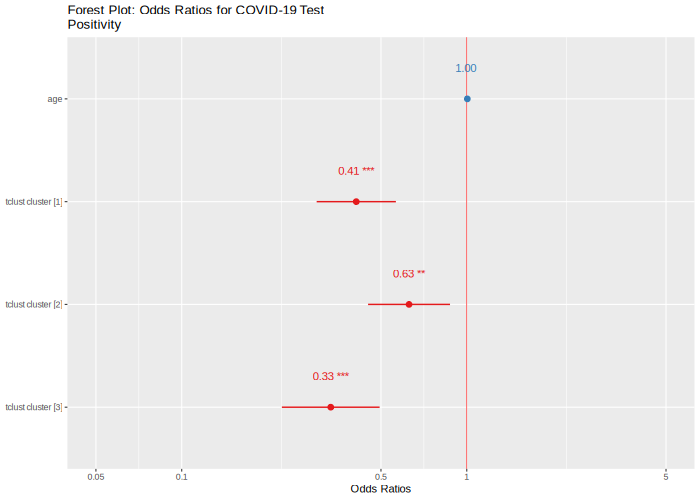


--- MARGINAL EFFECTS (PREDICTED PROBABILITY) ---


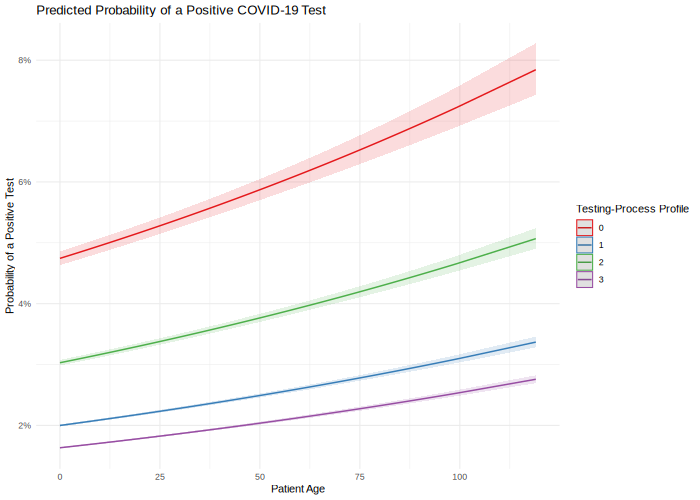

In [21]:
interpretation_code = '''
    # Ensure that the packages are installed and loaded
    if (!requireNamespace("sjPlot", quietly = TRUE)) install.packages("sjPlot", repos="https://cloud.r-project.org")
    if (!requireNamespace("ggeffects", quietly = TRUE)) install.packages("ggeffects", repos="https://cloud.r-project.org")

    library(sjPlot)
    library(ggeffects)
    library(ggplot2)

    # 1. Odds Ratios Forest Plot
    p1 <- plot_model(model, vline.color = "red",
                     title = "Forest Plot: Odds Ratios for COVID-19 Test Positivity",
                     show.values = TRUE, value.offset = .3)

    # Explicit save using print()
    png("forest_plot_OR.png", width=700, height=500)
    print(p1)
    dev.off()

    # 2. Predicted Marginal Effects (using tclust_cluster to match our model)
    pred_eff <- ggpredict(model, terms = c("age [all]", "tclust_cluster"))
    p2 <- plot(pred_eff) +
      labs(title = "Predicted Probability of a Positive COVID-19 Test",
           x = "Patient Age",
           y = "Probability of a Positive Test",
           color = "Testing-Process Profile") +
      theme_minimal()

    # Explicit save using print()
    png("marginal_effects.png", width=700, height=500)
    print(p2)
    dev.off()
'''

# Execute the R code
ro.r(interpretation_code)

# Verify that the files have been created and display them
print("--- ODDS RATIOS FOREST PLOT ---")
if os.path.exists("forest_plot_OR.png"):
    display(Image("forest_plot_OR.png"))
else:
    print("Error: The file forest_plot_OR.png was not generated by R.")

print("\n--- MARGINAL EFFECTS (PREDICTED PROBABILITY) ---")
if os.path.exists("marginal_effects.png"):
    display(Image("marginal_effects.png"))
else:
    print("Error: The file marginal_effects.png was not generated by R.")

## Conclusions & Critical Discussion of Predictive Performance (RQ3)

The analysis demonstrates the application of advanced multivariate statistical techniques to COVID-19 diagnostic testing data.

Model-Based Clustering and TCLUST identify heterogeneous demographic and testing-process profiles. However, these profiles should not be interpreted as distinct clinical risk groups.

The logistic GLMM accounts for heterogeneity across clinics and specimen-collection units within the CHOP healthcare setting.

On the held-out test set, the GLMM achieves modestly better predictive performance than standard logistic regression, with a PR-AUC of 0.0962, a ROC-AUC of 0.5989, and a Brier Score of 0.0576.

The patient-level bootstrap analysis (500 resamples) provides additional insight into the uncertainty of these performance differences. The 95% bootstrap confidence interval for the PR-AUC improvement ([0.0074, 0.0510]) excludes zero, supporting a positive improvement in precision-recall performance. In contrast, the confidence intervals for ROC-AUC ([-0.0019, 0.0722]) and Brier Score improvement ([-0.0002, 0.0014]) include zero, indicating that the evidence for improvements in these metrics is less conclusive. Therefore, the predictive advantage of the GLMM should be interpreted cautiously.

Nevertheless, the overall discriminative performance remains limited, suggesting that demographic and testing-process characteristics alone are insufficient for highly accurate predictions of test positivity.

The findings must also be interpreted considering repeated observations within patients, the sensitivity of clustering to modeling choices, and the retrospective nature of some process-related variables.

Overall, this project illustrates both the potential and the limitations of advanced multivariate methods when applied to heterogeneous real-world healthcare data.